
# House Prices Prediction

## Project Overview

Predicting residential property prices using the Kaggle **House Prices: Advanced Regression Techniques** dataset.

The project covers EDA, feature transformations, preprocessing, model comparison, hyperparameter tuning, and Kaggle submission.

**Key Results:**
- **Kaggle RMSLE:** 0.14772
- **Best CV RMSE:** 0.1306 — Gradient Boosting / Lasso
- **Final Model:** XGBoost
- **Final Holdout RMSE:** 0.12611 (log-price)

Models are trained on `log1p(SalePrice)` to reduce target skewness and align training with the competition metric.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    KFold,
    GridSearchCV,
    cross_val_score,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor

%matplotlib inline


## 1. Data Loading & Inspection

The dataset contains residential property characteristics, including size, quality, location, and construction details.

Initial checks cover dataset dimensions, feature types, duplicates, and missing values. The Kaggle test set does not contain the target `SalePrice`.


In [2]:
train_path = '/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv'
test_path = '/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv'

data_train = pd.read_csv(train_path)
data_test = pd.read_csv(test_path)


In [3]:
print(f'Train Shape: {data_train.shape}')
print(f'Train Columns: {data_train.columns}')
print(f'Test Shape: {data_test.describe()}')
print(f'Test Columns: {data_test.columns}')

Train Shape: (1460, 81)
Train Columns: Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'Garage

In [4]:
display(data_train.head())
display(data_train.describe())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:
data_train.dtypes.unique()

array([dtype('int64'), dtype('O'), dtype('float64')], dtype=object)

In [6]:
num_cols = [
    col for col in data_train.columns
    if pd.api.types.is_numeric_dtype(data_train[col])
    and col not in ['Id', 'SalePrice']
]

cat_cols = [
    col for col in data_train.columns
    if pd.api.types.is_object_dtype(data_train[col])        
]

print('Numerical columns:', num_cols, f'total {len(num_cols)} cols')
print('Categorical columns:', cat_cols, f'total {len(cat_cols)} cols')

Numerical columns: ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold'] total 36 cols
Categorical columns: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 


### Missing Values

Missing values require different treatment depending on their meaning. For some property features, `NaN` indicates absence (e.g., no garage or pool), rather than missing information.

Missing-value patterns are examined before imputation and feature transformations.


In [7]:
print( 'Train duplicates --', data_train.duplicated().any())
print('Test duplicates --', data_test.duplicated().any())

print('Train NA values --', data_train.isna().sum().sum())
print('Test NA values --', data_test.isna().sum().sum())

Train duplicates -- False
Test duplicates -- False
Train NA values -- 7829
Test NA values -- 7878


In [8]:
missing = (
    data_train.isna()
    .sum()
    .to_frame("missing_count")
)

missing["missing_pct"] = (
    missing["missing_count"] / len(data_train) * 100
)

missing = (
    missing[missing["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

missing

,missing_count,missing_pct
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


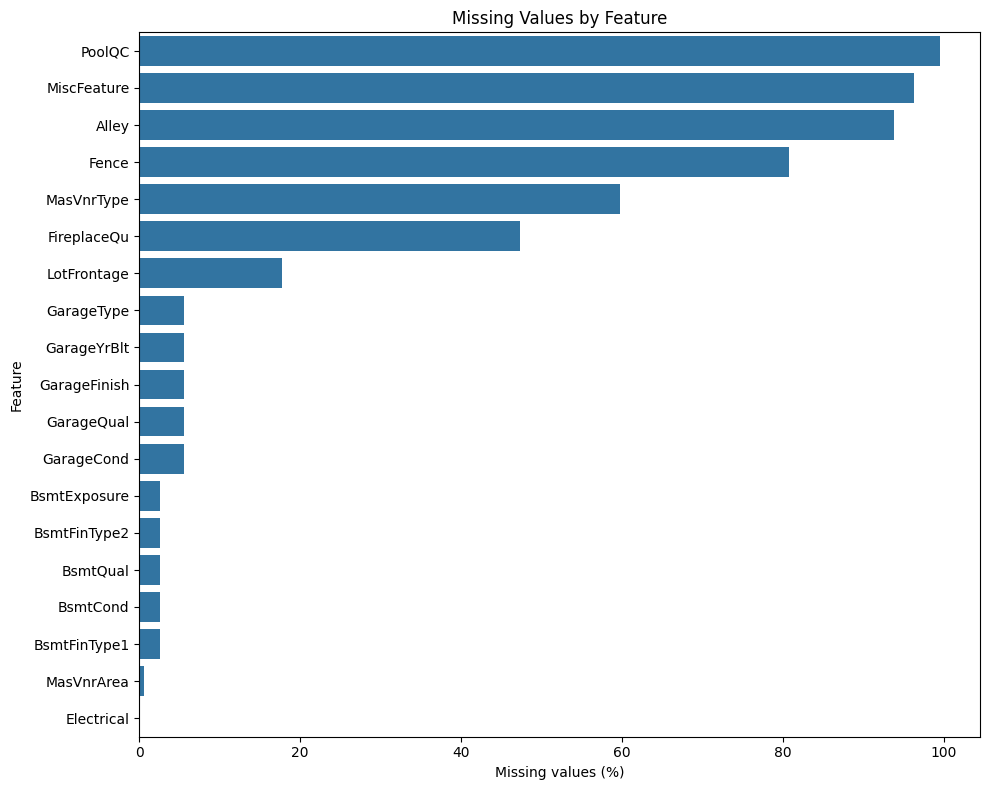

In [9]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=missing.reset_index(),
    x="missing_pct",
    y="index"
)

plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Missing Values by Feature")

plt.tight_layout()
plt.show()


## 2. Target Analysis

`SalePrice` is strongly right-skewed due to a small number of expensive properties.

Applying `log1p(SalePrice)` reduces skewness and makes the target more suitable for regression.

**Evaluation Metric:** RMSE on log-transformed prices, with Kaggle reporting RMSLE on original-scale predictions.


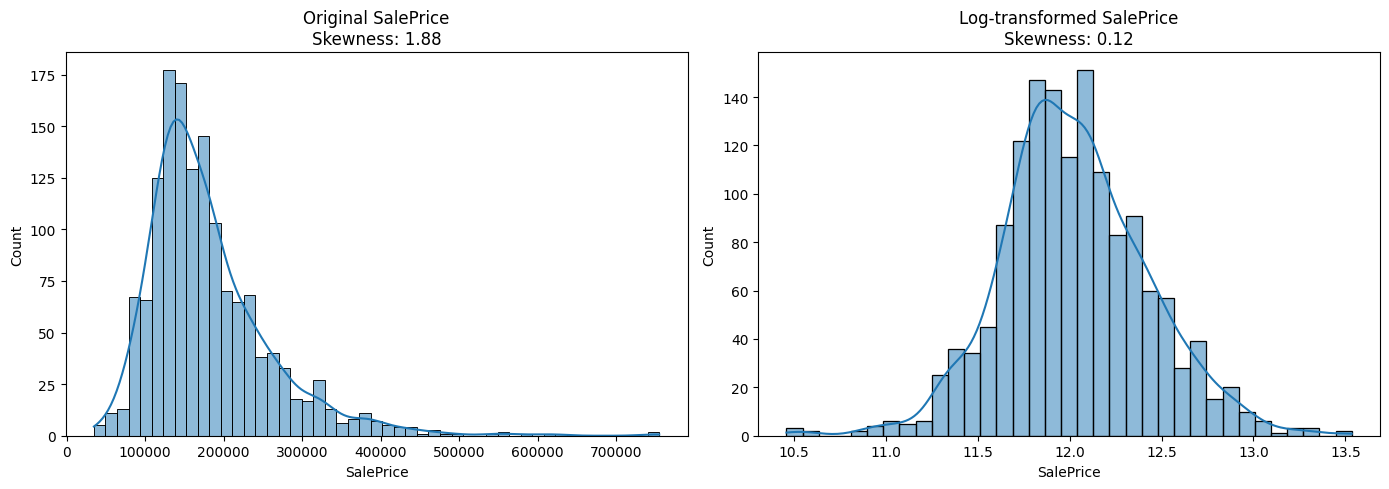

In [10]:
y = data_train["SalePrice"]
y_log = np.log1p(y)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(y, kde=True, ax=axes[0])
axes[0].set_title(
    f"Original SalePrice\nSkewness: {y.skew():.2f}"
)

sns.histplot(y_log, kde=True, ax=axes[1])
axes[1].set_title(
    f"Log-transformed SalePrice\nSkewness: {y_log.skew():.2f}"
)

plt.tight_layout()
plt.show()

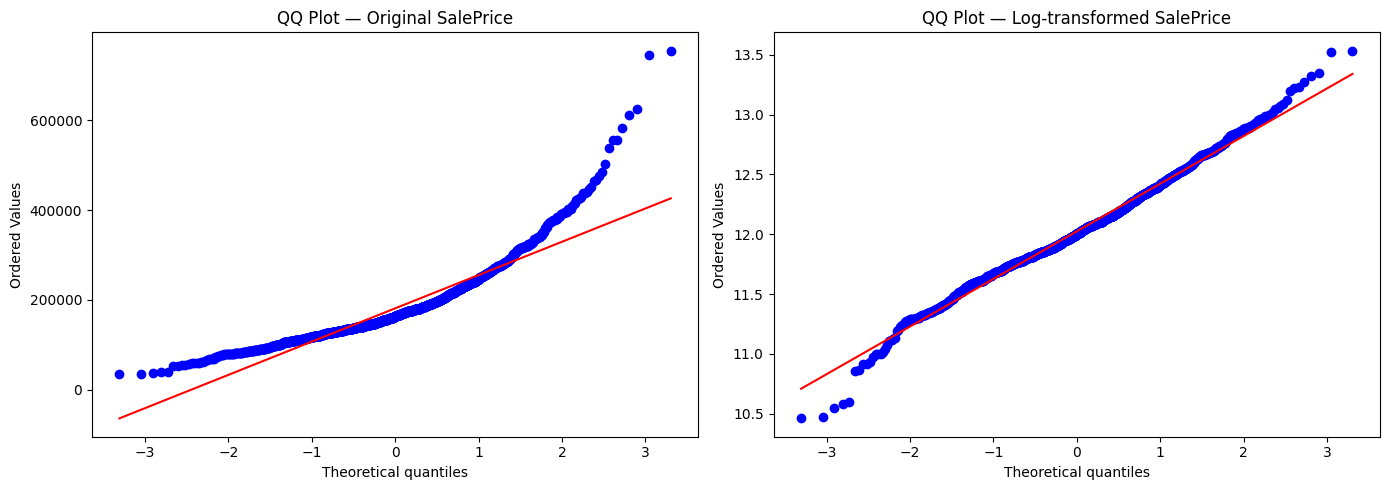

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

stats.probplot(y, dist="norm", plot=axes[0])
axes[0].set_title("QQ Plot — Original SalePrice")

stats.probplot(y_log, dist="norm", plot=axes[1])
axes[1].set_title("QQ Plot — Log-transformed SalePrice")

plt.tight_layout()
plt.show()


### Key Findings

- Original sale prices have a pronounced right tail.
- Log transformation produces a more symmetric distribution.
- The transformed target is used throughout model training.

Final predictions are converted back to the original price scale using `expm1`.


Skewness: 0.121347
Kurtosis: 0.809519


/tmp/ipykernel_17/2031490941.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data_train['SalePrice_Log']);


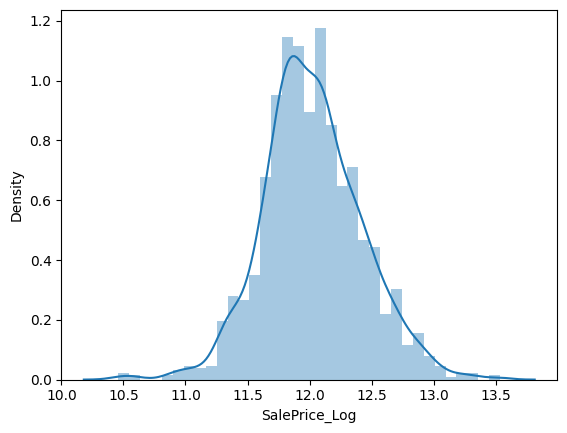

In [12]:
data_train['SalePrice_Log'] = np.log1p(data_train['SalePrice'])

sns.distplot(data_train['SalePrice_Log']);

print("Skewness: %f" % data_train['SalePrice_Log'].skew())
print("Kurtosis: %f" % data_train['SalePrice_Log'].kurt())

data_train.drop('SalePrice', axis= 1, inplace=True)

In [13]:
cols_fillna = ['PoolQC','MiscFeature','Alley','Fence','MasVnrType','FireplaceQu',
               'GarageQual','GarageCond','GarageFinish','GarageType', 'Electrical',
               'KitchenQual', 'SaleType', 'Functional', 'Exterior2nd', 'Exterior1st',
               'BsmtExposure','BsmtCond','BsmtQual','BsmtFinType1','BsmtFinType2',
               'MSZoning', 'Utilities']

for col in cols_fillna:
    data_train[col].fillna('None',inplace=True)
    data_test[col].fillna('None',inplace=True)

/tmp/ipykernel_17/1616180909.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data_train[col].fillna('None',inplace=True)
/tmp/ipykernel_17/1616180909.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df


## 3. Data Preparation & Feature Transformations

Categorical missing values are handled according to feature semantics, while numerical missing values are imputed.

Skewed numerical features, including living area and lot area, are log-transformed to reduce the influence of extreme values.

The same feature transformations are applied to the Kaggle test dataset.


In [14]:
total = data_train.isnull().sum().sort_values(ascending=False)
percent = (data_train.isnull().sum()/data_train.isnull().count()).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])
missing_data.head(5)

,Total,Percent
LotFrontage,259,0.177397
GarageYrBlt,81,0.055479
MasVnrArea,8,0.005479
Id,0,0.000000
MSSubClass,0,0.000000


In [15]:
def log_trans(data, cols):
    res = []
    for col in cols:
        new_name = col + '_log'
        data[new_name] = np.log1p(data[col])
        
        old_skew = data[col].skew()
        old_kurt = data[col].kurt()
        
        new_skew = data[new_name].skew()
        new_kurt = data[new_name].kurt()
        
        
        print(f'\n{col}')
        print('-'*45)
        print(f'Original:')
        print(f'  Skewness: {old_skew:.3f}')
        print(f'  Kurtosis: {old_kurt:.3f}')
        print(f'Log transformed:')
        print(f'  Skewness: {new_skew:.3f}')
        print(f'  Kurtosis: {new_kurt:.3f}')
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        stats.probplot(
            data[col],
            dist="norm",
            plot=axes[0]
        )
        
        axes[0].set_title(
            f'{col}\n'
            f'Skew={old_skew:.2f}, Kurt={old_kurt:.2f}'
        )
        
        stats.probplot(
            data[new_name],
            dist="norm",
            plot=axes[1]
        )
        
        axes[1].set_title(
            f'{new_name}\n'
            f'Skew={new_skew:.2f}, Kurt={new_kurt:.2f}'
        )
        
        
        plt.tight_layout()
        plt.show()


LotArea
---------------------------------------------
Original:
  Skewness: 12.208
  Kurtosis: 203.243
Log transformed:
  Skewness: -0.137
  Kurtosis: 4.714


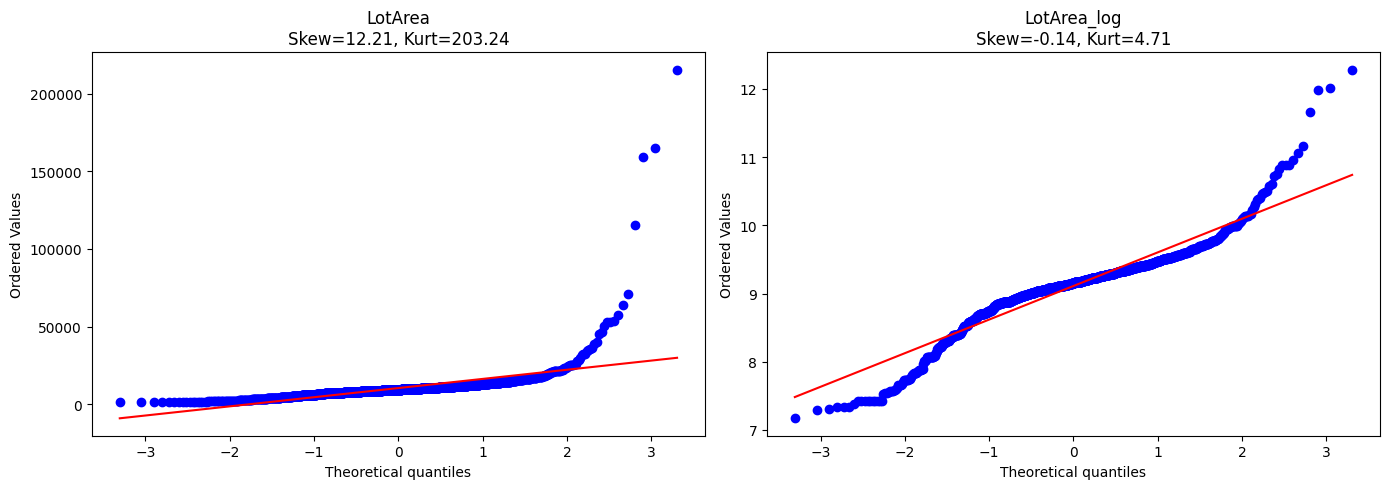


GarageArea
---------------------------------------------
Original:
  Skewness: 0.180
  Kurtosis: 0.917
Log transformed:
  Skewness: -3.483
  Kurtosis: 11.176


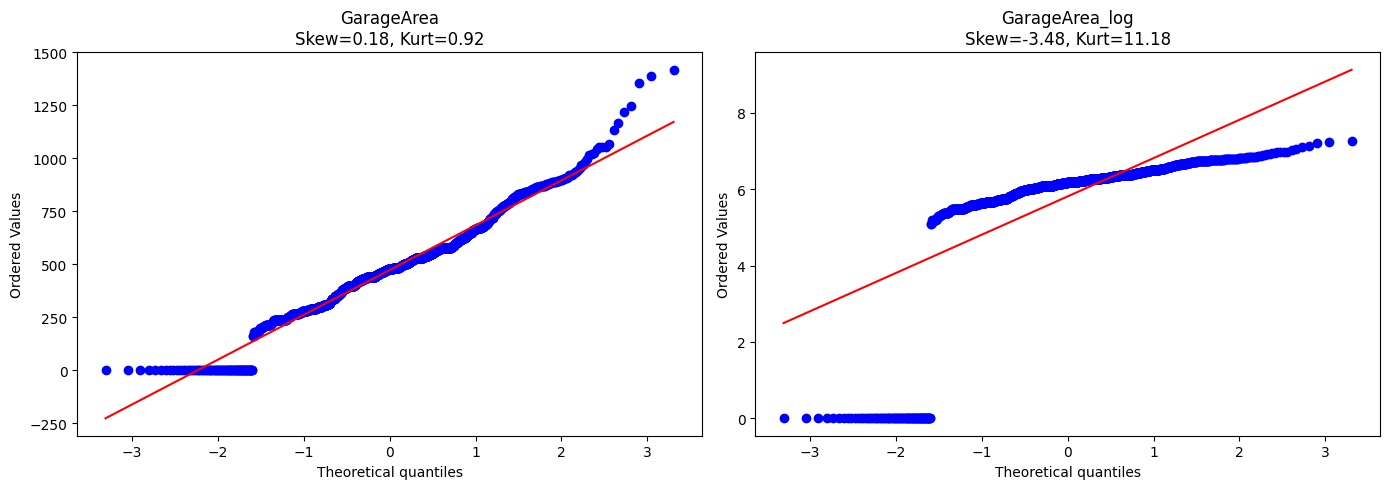


GrLivArea
---------------------------------------------
Original:
  Skewness: 1.367
  Kurtosis: 4.895
Log transformed:
  Skewness: -0.006
  Kurtosis: 0.282


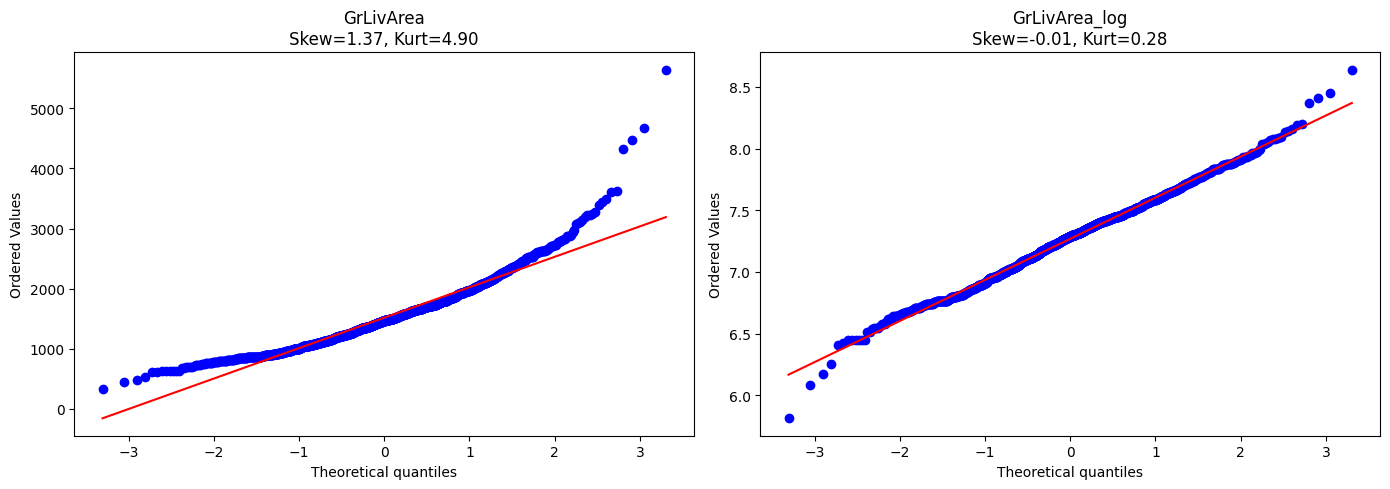


1stFlrSF
---------------------------------------------
Original:
  Skewness: 1.377
  Kurtosis: 5.746
Log transformed:
  Skewness: 0.080
  Kurtosis: 0.151


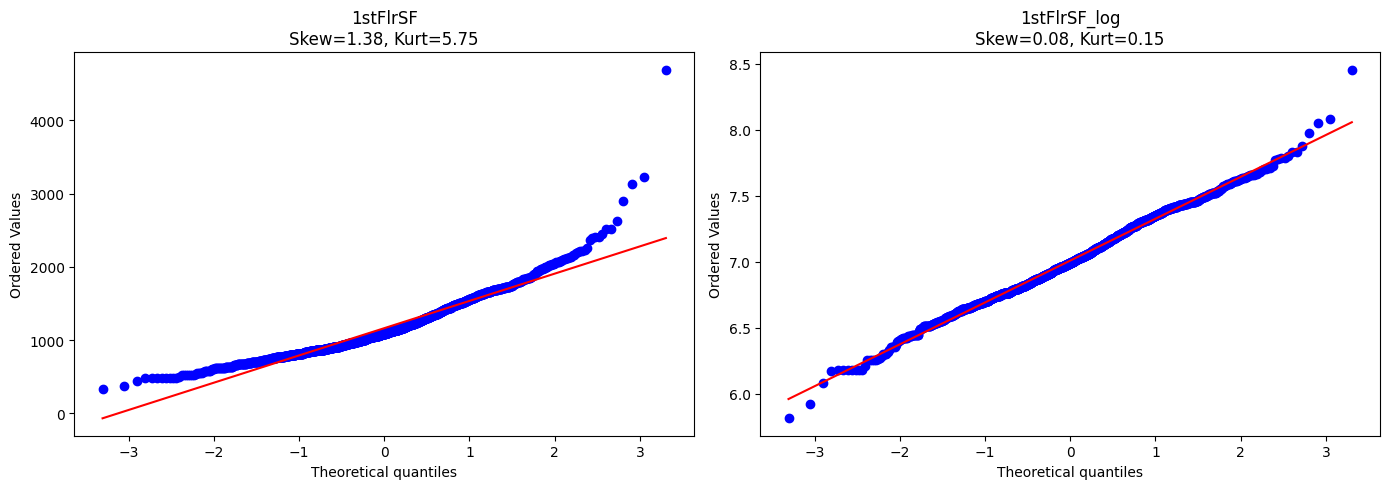


TotalBsmtSF
---------------------------------------------
Original:
  Skewness: 1.524
  Kurtosis: 13.250
Log transformed:
  Skewness: -5.155
  Kurtosis: 27.740


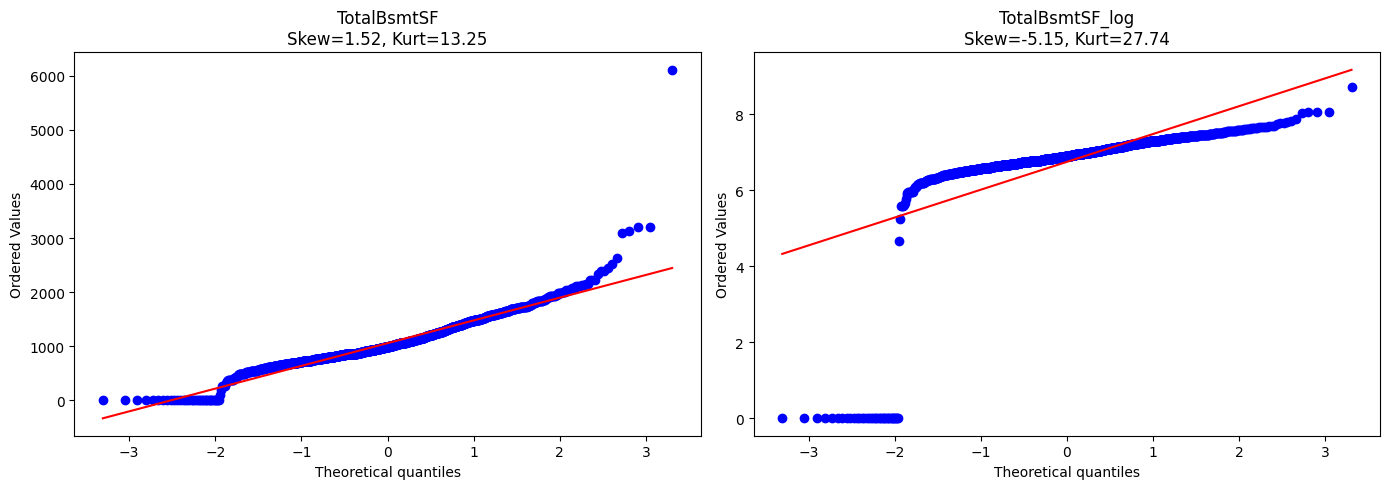


LotFrontage
---------------------------------------------
Original:
  Skewness: 2.164
  Kurtosis: 17.453
Log transformed:
  Skewness: -0.729
  Kurtosis: 2.309


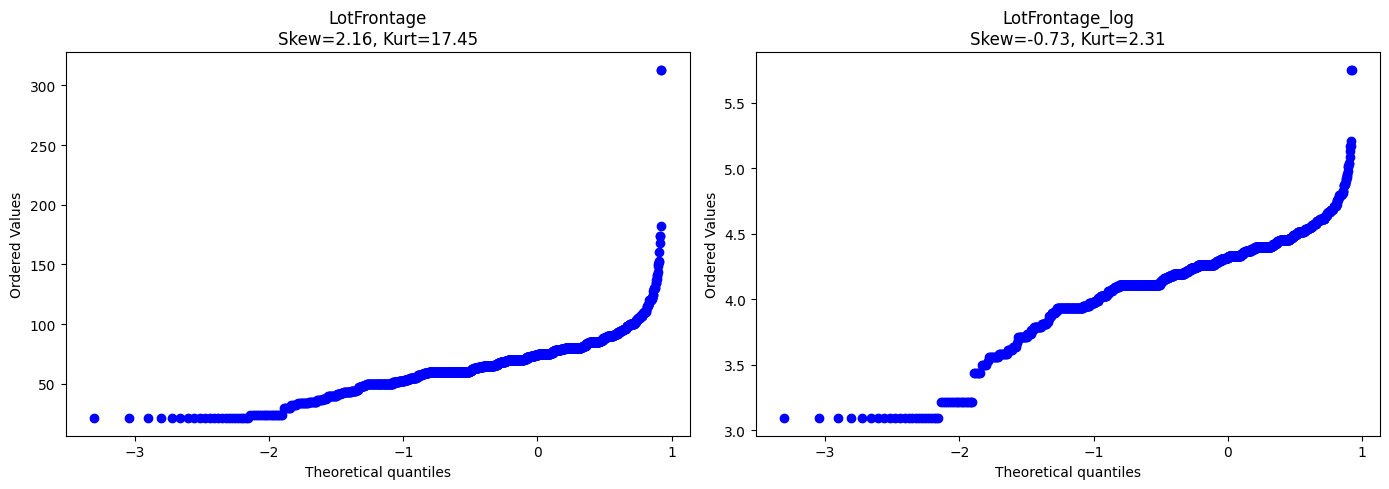


KitchenAbvGr
---------------------------------------------
Original:
  Skewness: 4.488
  Kurtosis: 21.532
Log transformed:
  Skewness: 3.869
  Kurtosis: 20.057


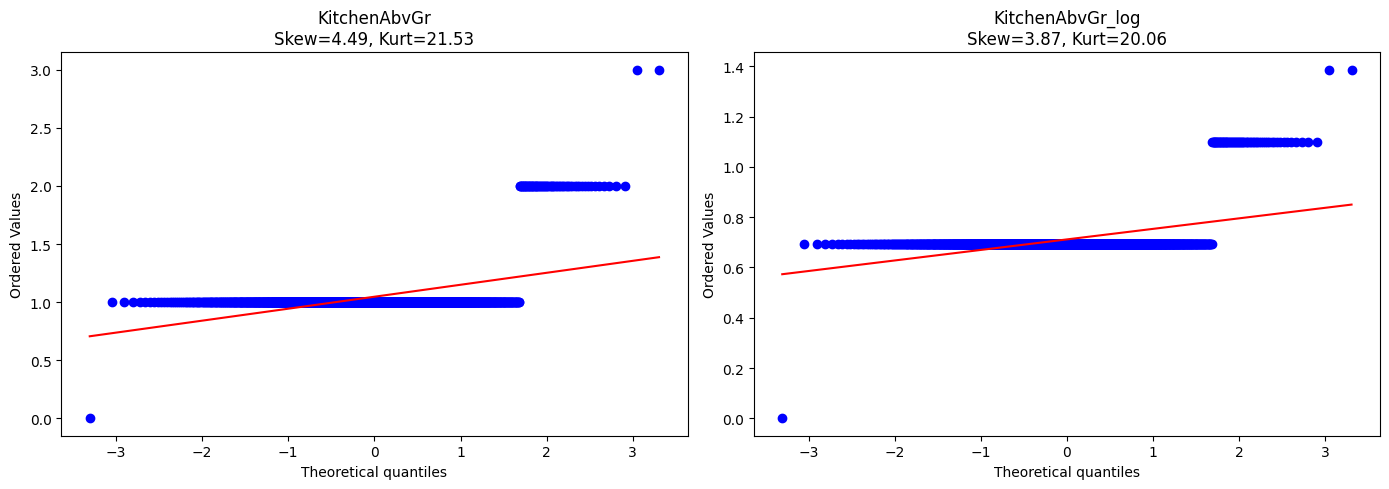

In [16]:
log_trans(data_train, ['LotArea', 'GarageArea', 'GrLivArea', '1stFlrSF', "TotalBsmtSF", 'LotFrontage', 'KitchenAbvGr'])

In [17]:
for i in ['LotArea', 'GarageArea', 'GrLivArea', '1stFlrSF', "TotalBsmtSF", 'LotFrontage', 'KitchenAbvGr']:
    if i in ['LotFrontage', '1stFlrSF', 'GrLivArea', 'LotArea']:
        data_train.drop(i, inplace=True, axis=1)
    else:
        data_train.drop(i+'_log', inplace=True, axis=1)

In [18]:
num_cols = [
    col for col in data_train.columns
    if pd.api.types.is_numeric_dtype(data_train[col])
    and col not in ['Id', 'SalePrice_Log']
]
print(f'New num cols:{num_cols}, total: {len(num_cols)} cols')

New num cols:['MSSubClass', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '2ndFlrSF', 'LowQualFinSF', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'LotArea_log', 'GrLivArea_log', '1stFlrSF_log', 'LotFrontage_log'], total: 36 cols



LotFrontage
---------------------------------------------
Original:
  Skewness: 0.662
  Kurtosis: 2.587
Log transformed:
  Skewness: -0.972
  Kurtosis: 1.835


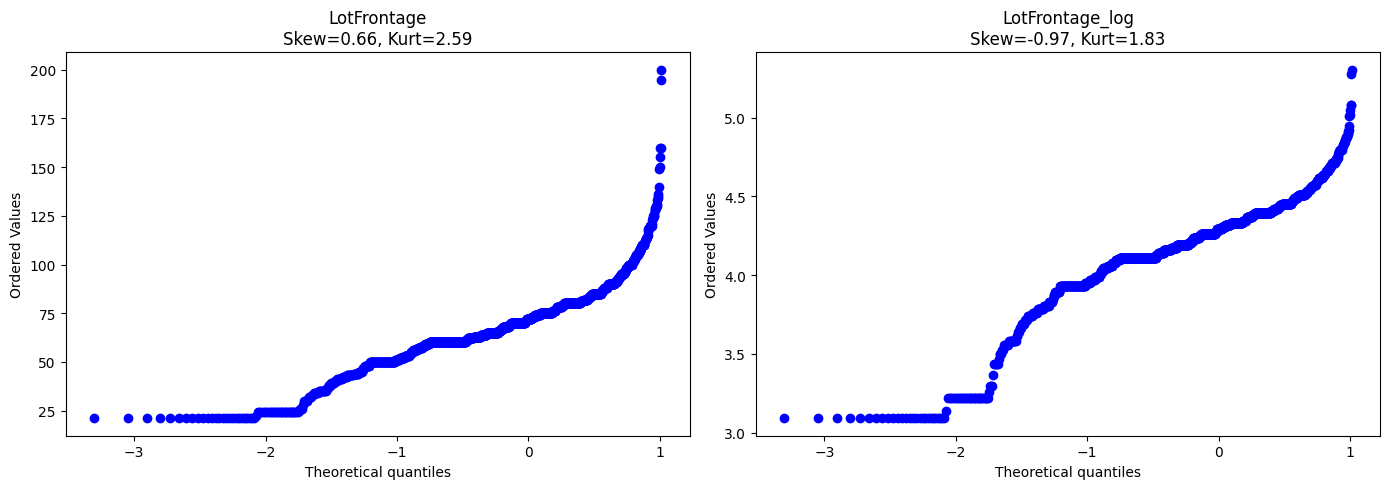


1stFlrSF
---------------------------------------------
Original:
  Skewness: 1.558
  Kurtosis: 8.054
Log transformed:
  Skewness: 0.053
  Kurtosis: 0.165


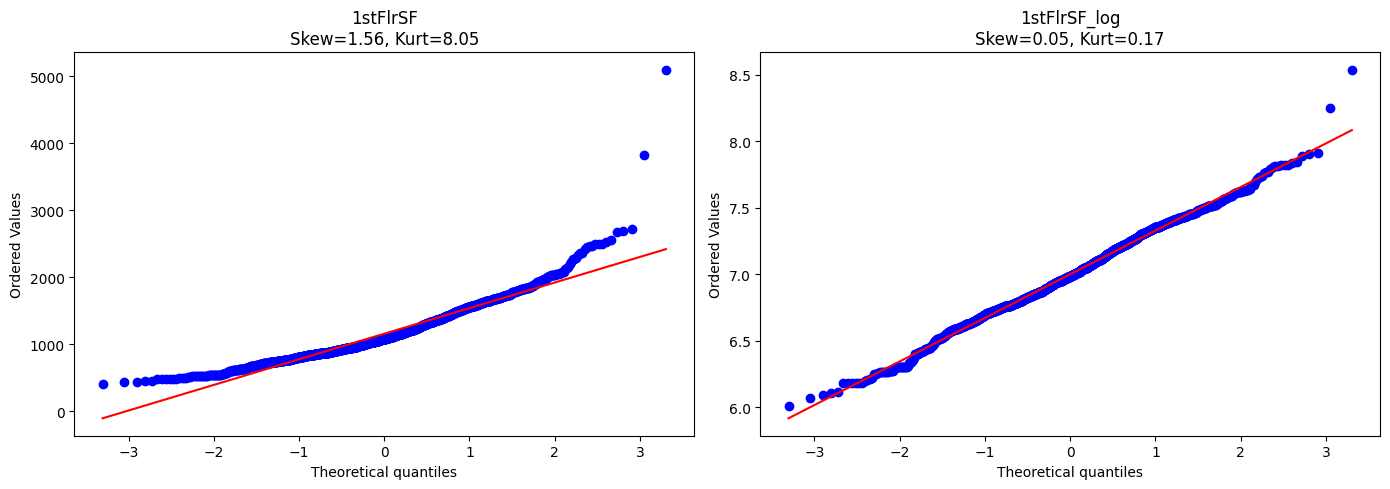


GrLivArea
---------------------------------------------
Original:
  Skewness: 1.130
  Kurtosis: 2.920
Log transformed:
  Skewness: 0.028
  Kurtosis: 0.113


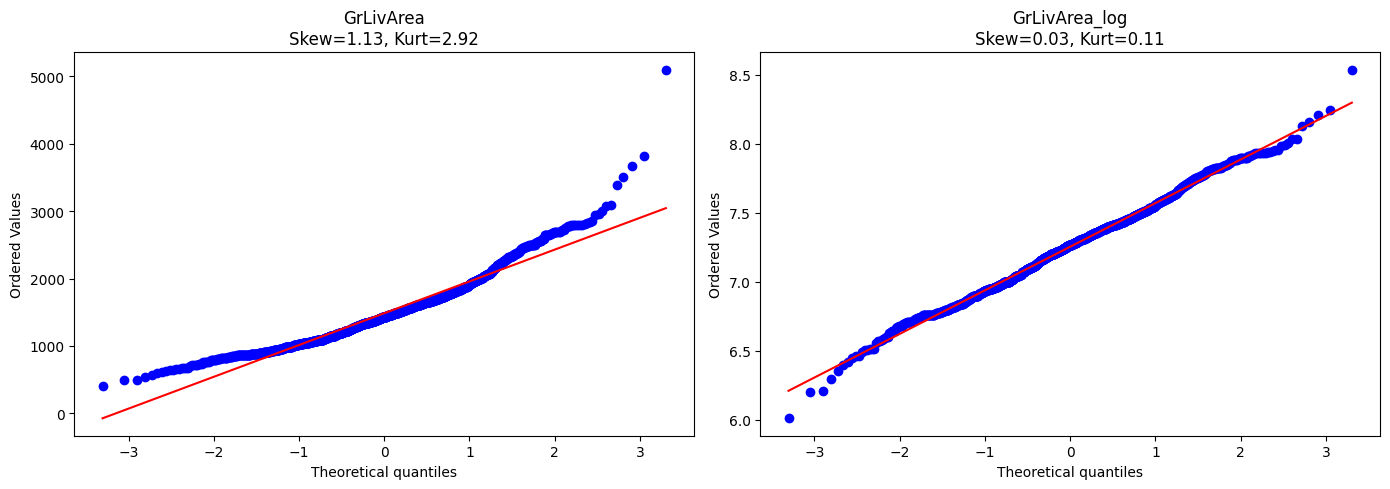


LotArea
---------------------------------------------
Original:
  Skewness: 3.115
  Kurtosis: 20.747
Log transformed:
  Skewness: -0.916
  Kurtosis: 2.593


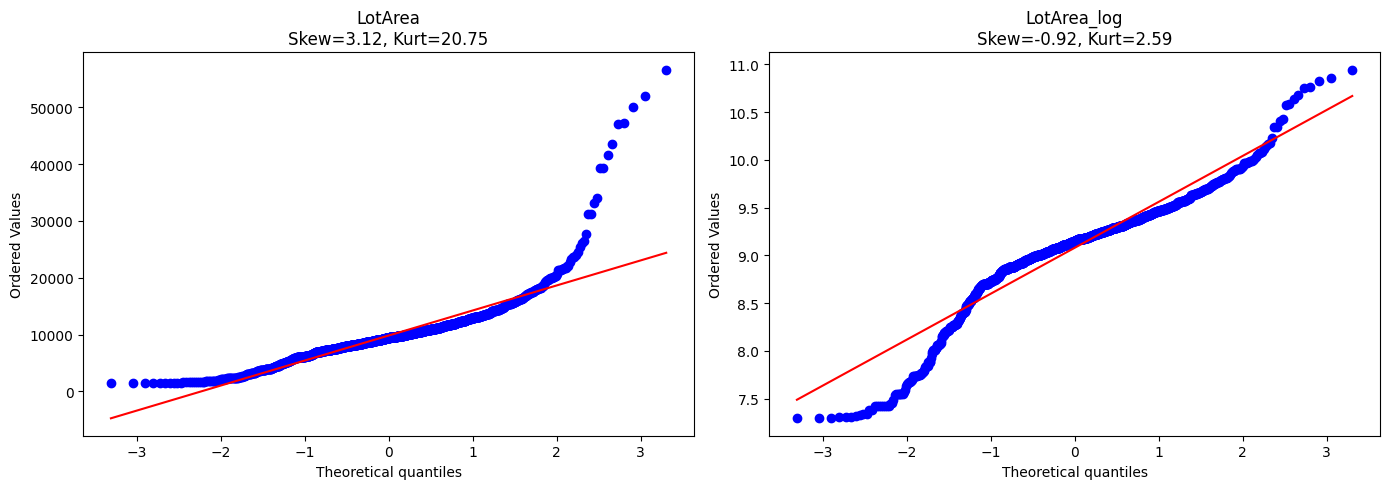

In [19]:
log_trans(data_test, ['LotFrontage', '1stFlrSF', 'GrLivArea', 'LotArea'])
for i in ['LotFrontage', '1stFlrSF', 'GrLivArea', 'LotArea']:
    data_test.drop(i, inplace=True, axis=1)


## 4. Feature Relationships & Outlier Analysis

Numerical features are examined for their relationships with log-transformed sale prices.

Particular attention is given to property quality, living area, and unusual observations. Extreme price–feature combinations are investigated before model training.


In [20]:
eda_data = data_train.drop(columns="SalePrice_Log").copy()
eda_data["SalePrice_Log"] = data_train["SalePrice_Log"].copy()

numeric_corr = (
    eda_data
    .select_dtypes(include=np.number)
    .corr()["SalePrice_Log"]
    .drop("SalePrice_Log")
    .sort_values(key=abs, ascending=False)
)

numeric_corr.head(15)

OverallQual      0.817185
GrLivArea_log    0.730254
GarageCars       0.680625
GarageArea       0.650888
TotalBsmtSF      0.612134
1stFlrSF_log     0.608955
FullBath         0.594771
YearBuilt        0.586570
YearRemodAdd     0.565608
GarageYrBlt      0.541073
TotRmsAbvGrd     0.534422
Fireplaces       0.489450
MasVnrArea       0.430809
LotArea_log      0.399923
BsmtFinSF1       0.372023
Name: SalePrice_Log, dtype: float64

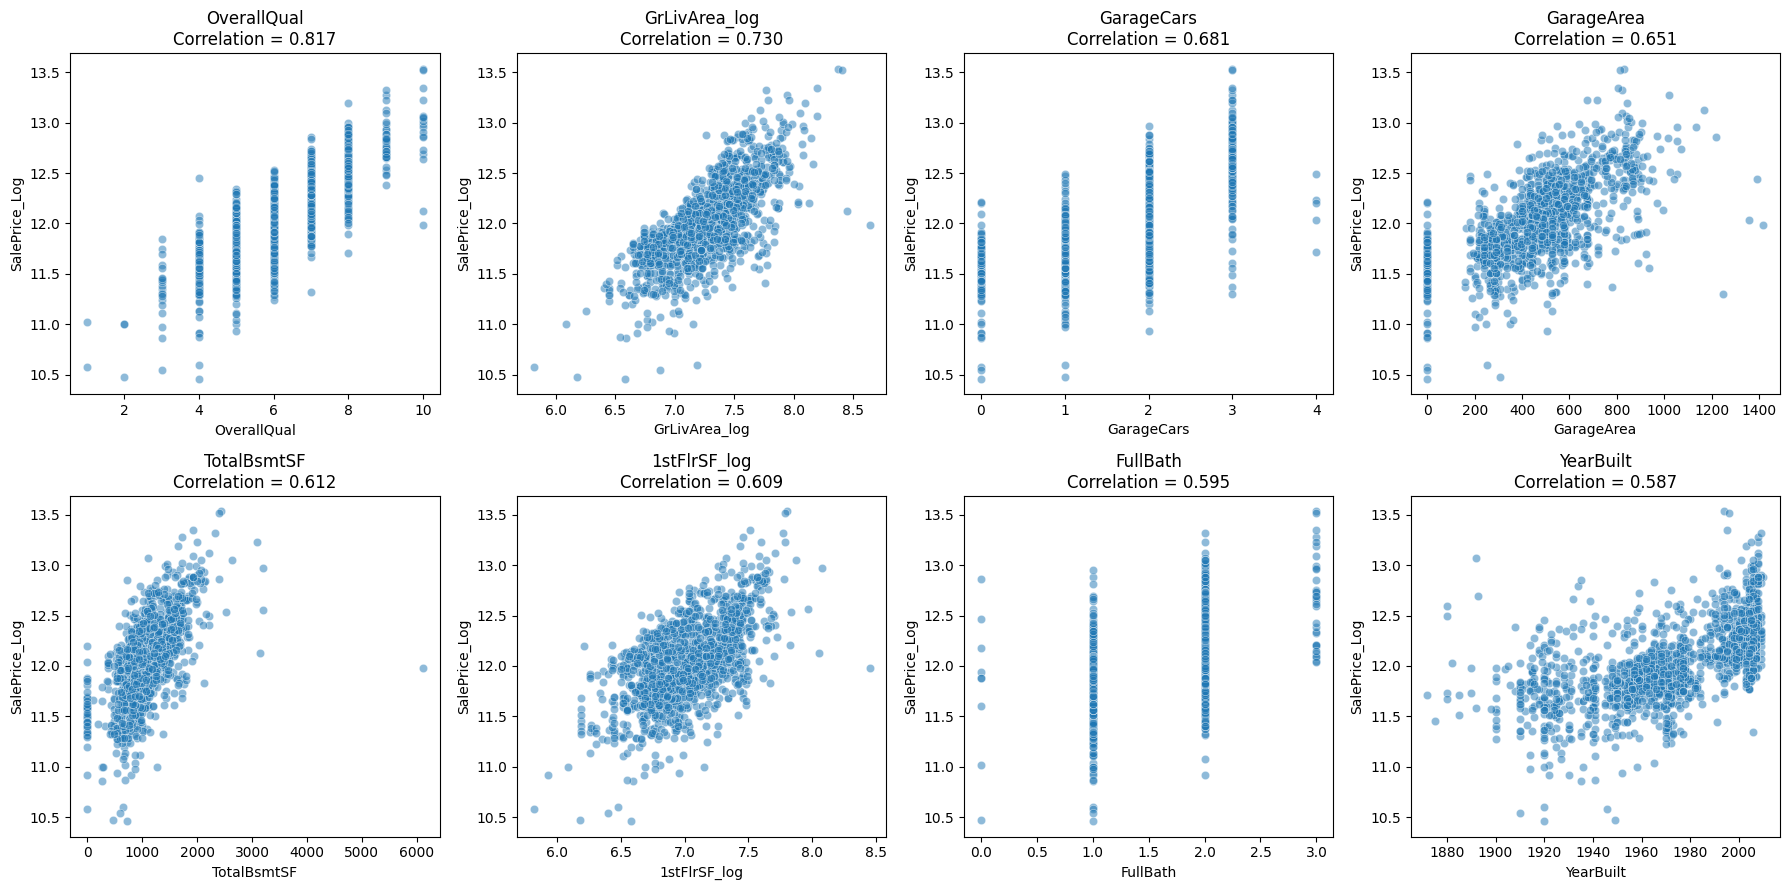

In [21]:
top_numeric_features = numeric_corr.head(8).index

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for ax, col in zip(axes, top_numeric_features):
    sns.scatterplot(
        data=eda_data,
        x=col,
        y="SalePrice_Log",
        alpha=0.5,
        ax=ax
    )

    ax.set_title(
        f"{col}\nCorrelation = {numeric_corr[col]:.3f}"
    )

plt.tight_layout()
plt.show()

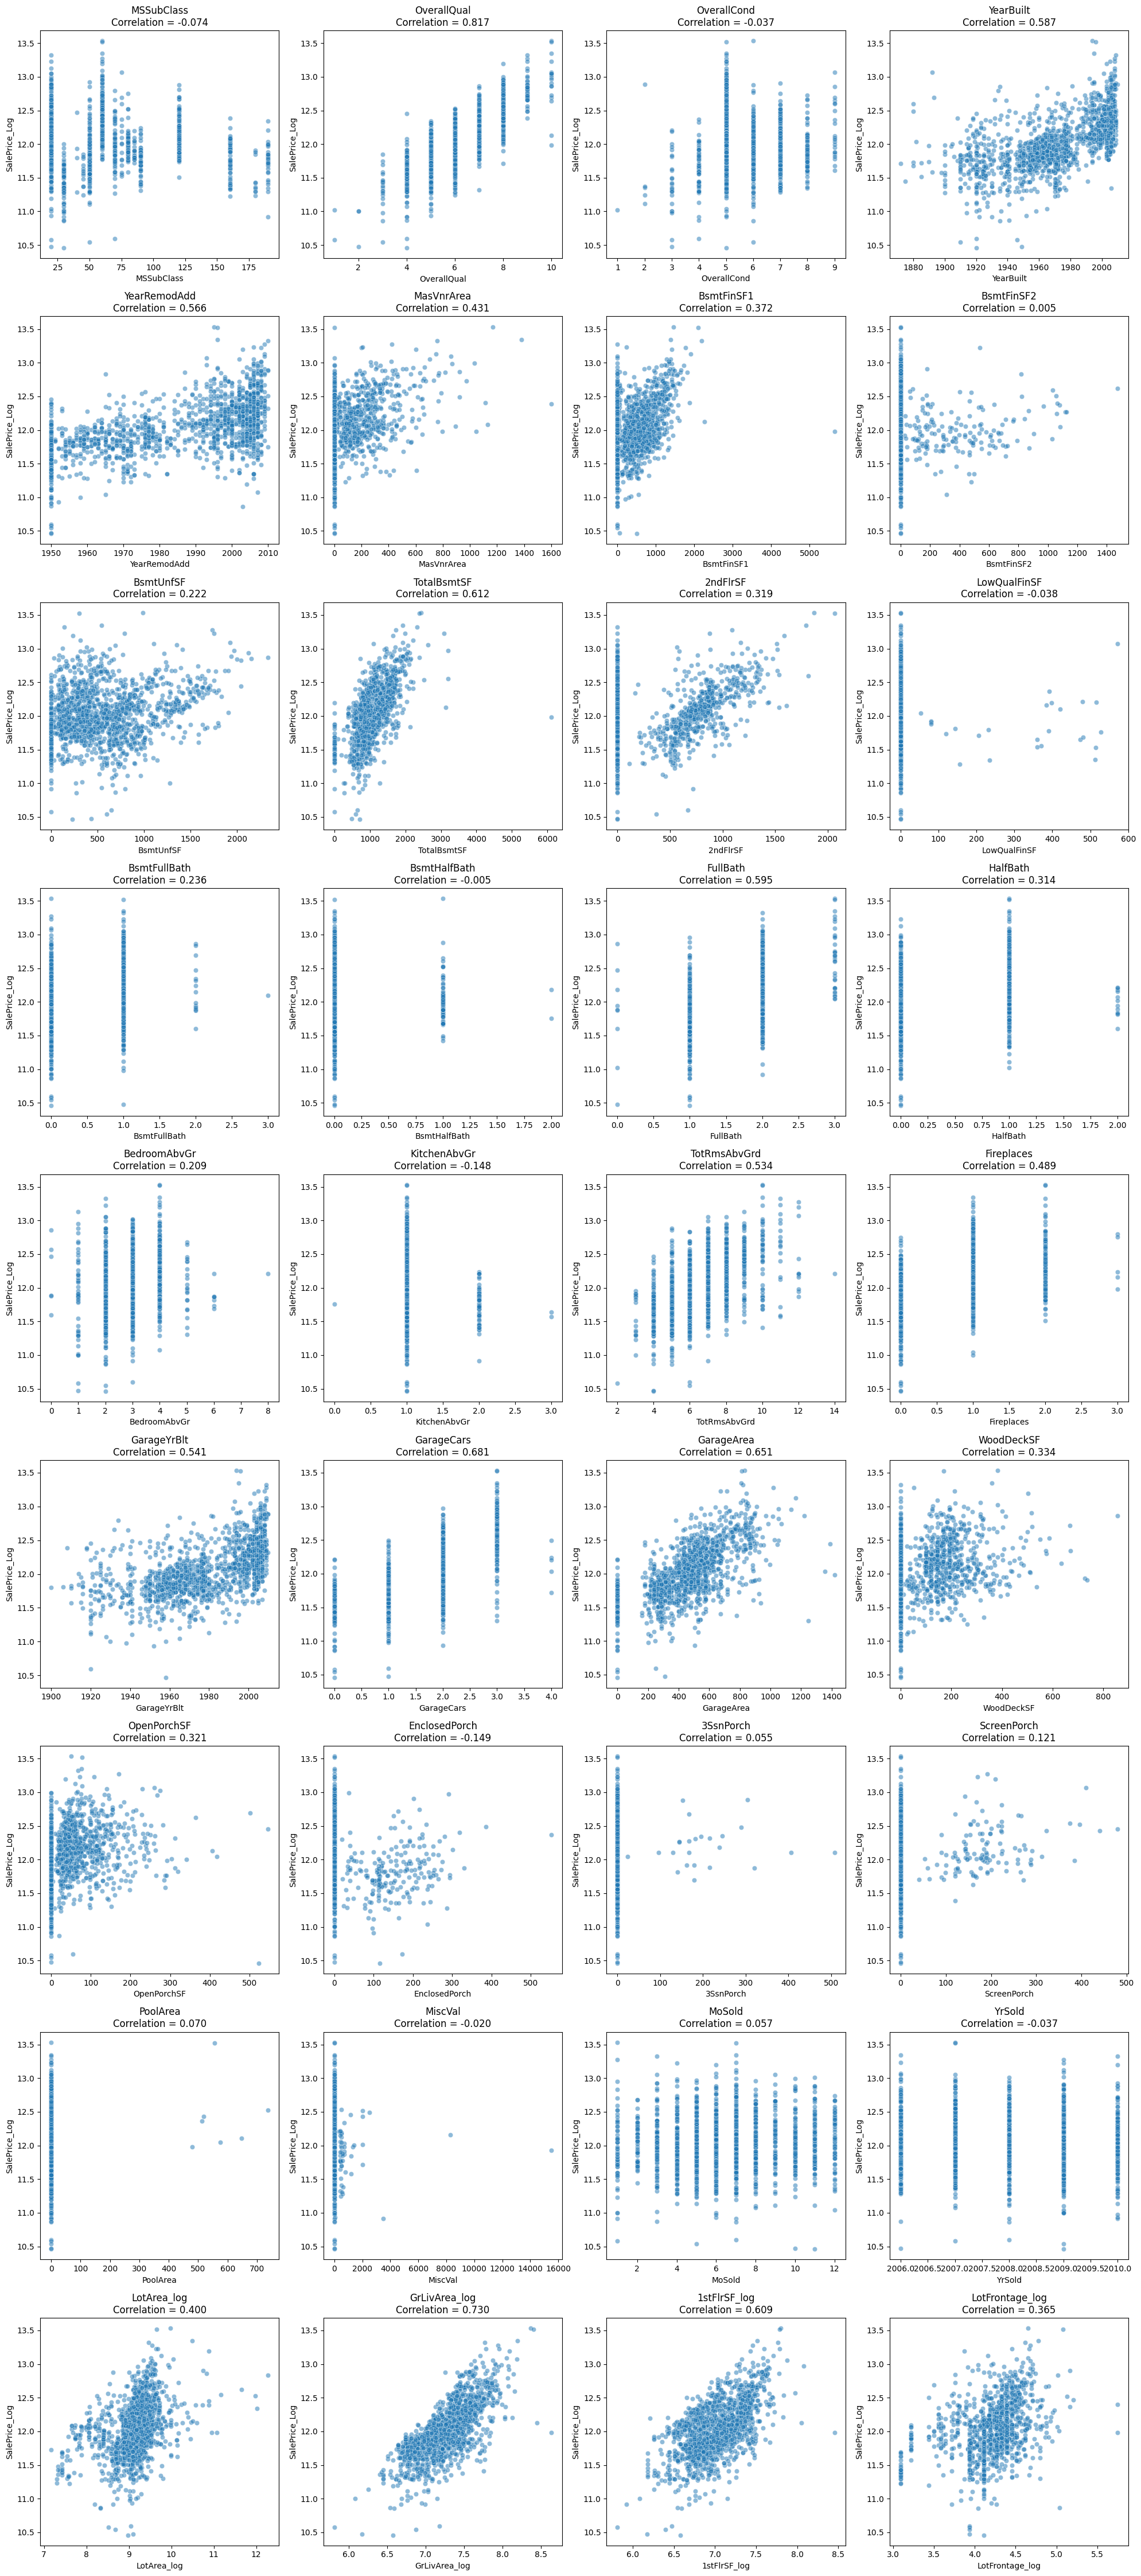

In [22]:
target = 'SalePrice_Log'

n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))


fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 5)
)

axes = axes.flatten()


for ax, col in zip(axes, num_cols):
    
    corr = data_train[[col, target]].corr().iloc[0, 1]
    
    sns.scatterplot(
        data=data_train,
        x=col,
        y=target,
        ax=ax,
        alpha=0.5
    )
    
    ax.set_title(
        f'{col}\nCorrelation = {corr:.3f}',
        fontsize=12
    )
    
    ax.set_xlabel(col)
    ax.set_ylabel(target)


for ax in axes[len(num_cols):]:
    ax.remove()


plt.tight_layout()
plt.show()

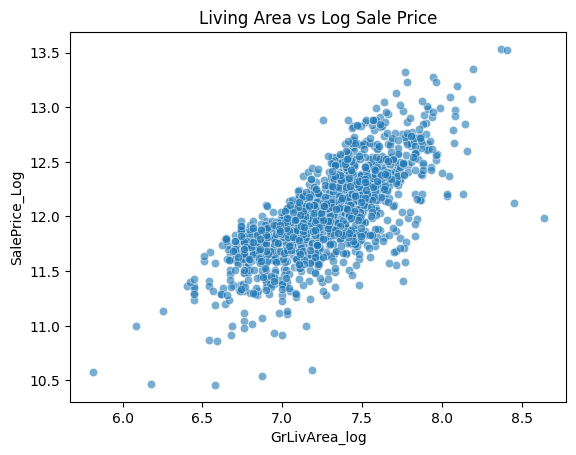

In [23]:
sns.scatterplot(
    data=data_train,
    x='GrLivArea_log',
    y='SalePrice_Log',
    alpha=0.6
)

plt.title("Living Area vs Log Sale Price")
plt.show()

In [24]:
data_train = data_train.drop(
    data_train[(data_train['OverallQual']==10) & (data_train['SalePrice_Log']<12.3)].index)
data_train = data_train.drop(
    data_train[(data_train['GrLivArea_log']>8.3) & (data_train['SalePrice_Log']<12.5)].index)

In [25]:
corr = data_train[num_cols + ['SalePrice_Log']].corr()
corr_abs = corr.abs()
min_val_corr = 0.4
target = 'SalePrice_Log'
nr_num_cols = len(num_cols)
ser_corr = corr_abs.nlargest(nr_num_cols, target)[target]

cols_abv_corr_limit = list(ser_corr[ser_corr.values > min_val_corr].index)
cols_bel_corr_limit = list(ser_corr[ser_corr.values <= min_val_corr].index)

In [26]:
print(ser_corr)
print("*"*30)
print("List of numerical features with corr above min_val_corr :")
print(cols_abv_corr_limit)
print("*"*30)
print("List of numerical features with corr below min_val_corr :")
print(cols_bel_corr_limit)

SalePrice_Log      1.000000
OverallQual        0.821405
GrLivArea_log      0.737431
GarageCars         0.681033
GarageArea         0.656129
TotalBsmtSF        0.647563
1stFlrSF_log       0.615408
FullBath           0.595899
YearBuilt          0.587043
YearRemodAdd       0.565992
GarageYrBlt        0.541638
TotRmsAbvGrd       0.537702
Fireplaces         0.491998
MasVnrArea         0.434621
LotArea_log        0.402820
BsmtFinSF1         0.392283
LotFrontage_log    0.368164
WoodDeckSF         0.334251
OpenPorchSF        0.325215
2ndFlrSF           0.319953
HalfBath           0.314186
BsmtFullBath       0.237099
BsmtUnfSF          0.221892
BedroomAbvGr       0.209035
EnclosedPorch      0.149029
KitchenAbvGr       0.147534
ScreenPorch        0.121245
PoolArea           0.074338
MSSubClass         0.073969
MoSold             0.057064
3SsnPorch          0.054914
LowQualFinSF       0.037951
YrSold             0.037151
OverallCond        0.036821
MiscVal            0.020012
BsmtHalfBath       0

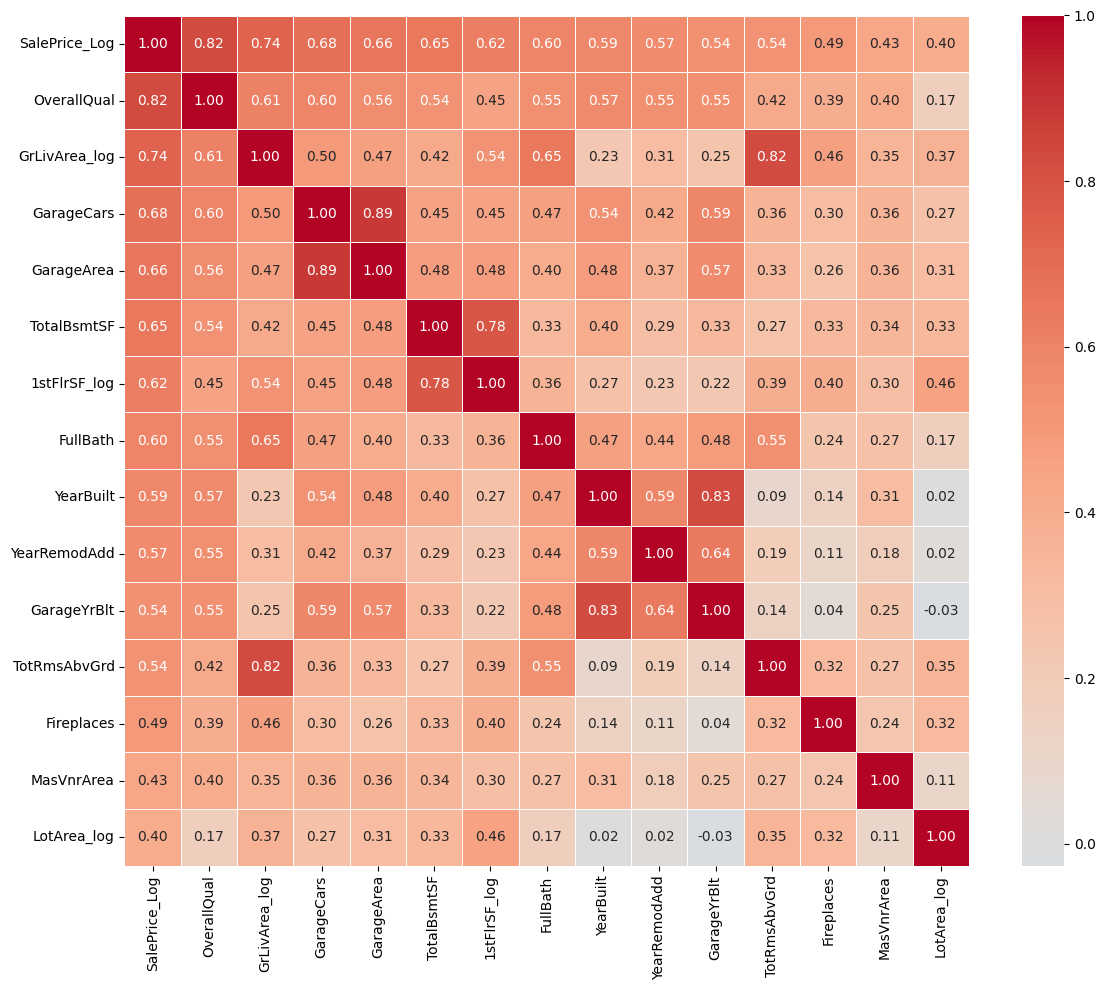

In [27]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr.loc[cols_abv_corr_limit, cols_abv_corr_limit],
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.tight_layout()
plt.show()


### Numerical Feature Findings

- Overall property quality and living area are important price-related features.
- Garage and basement characteristics also show meaningful relationships.
- Several predictors are strongly correlated, suggesting potential multicollinearity.

Ridge and Lasso are included to evaluate the benefits of regularization.


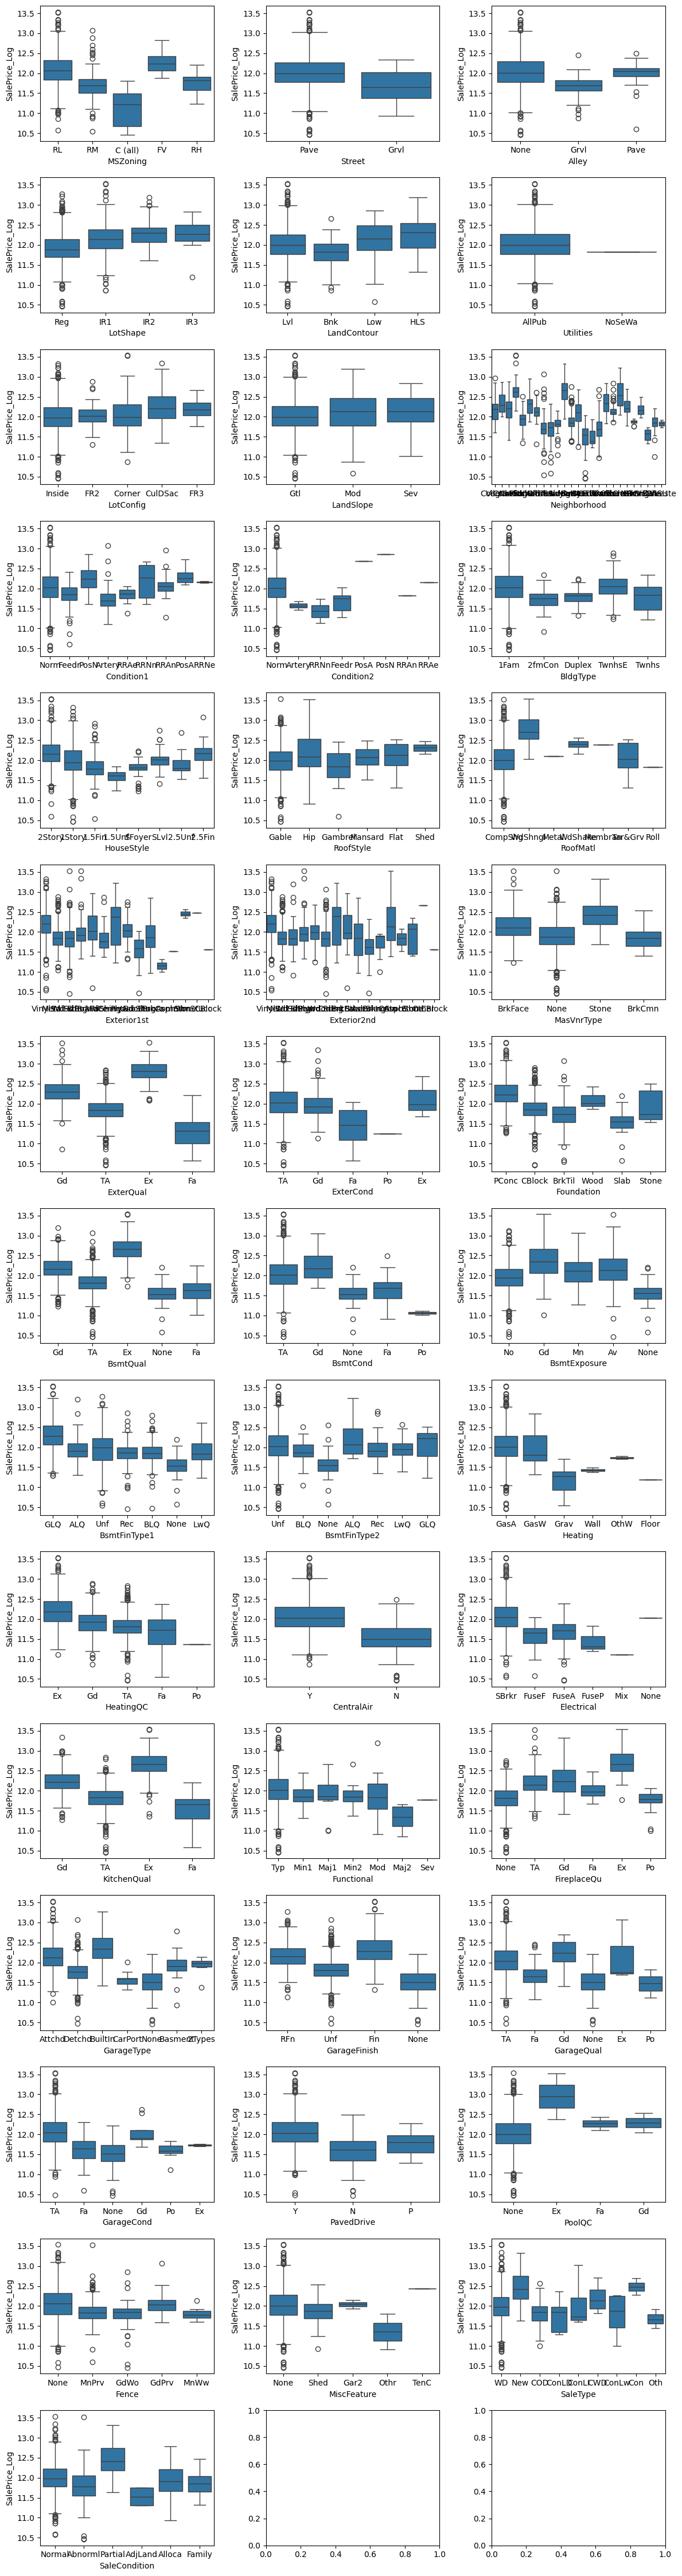

In [28]:
li_cat_feats = list(cat_cols)
nr_rows = 15
nr_cols = 3

fig, axs = plt.subplots(nr_rows, nr_cols, figsize=(nr_cols*4,nr_rows*3))

for r in range(0,nr_rows):
    for c in range(0,nr_cols):  
        i = r*nr_cols+c
        if i < len(li_cat_feats):
            sns.boxplot(x=li_cat_feats[i], y=target, data=data_train, ax = axs[r][c])
    
plt.tight_layout()    
plt.show()   

In [29]:
def categorical_anova(data, categorical_cols, target_col):
    results = []

    for col in categorical_cols:
        groups = [
            group[target_col].dropna().values
            for _, group in data.groupby(col, dropna=False)
        ]

        groups = [group for group in groups if len(group) > 0]

        if len(groups) > 1:
            _, p_value = stats.f_oneway(*groups)

            results.append({
                "feature": col,
                "p_value": p_value
            })

    return (
        pd.DataFrame(results)
        .sort_values("p_value")
        .reset_index(drop=True)
    )

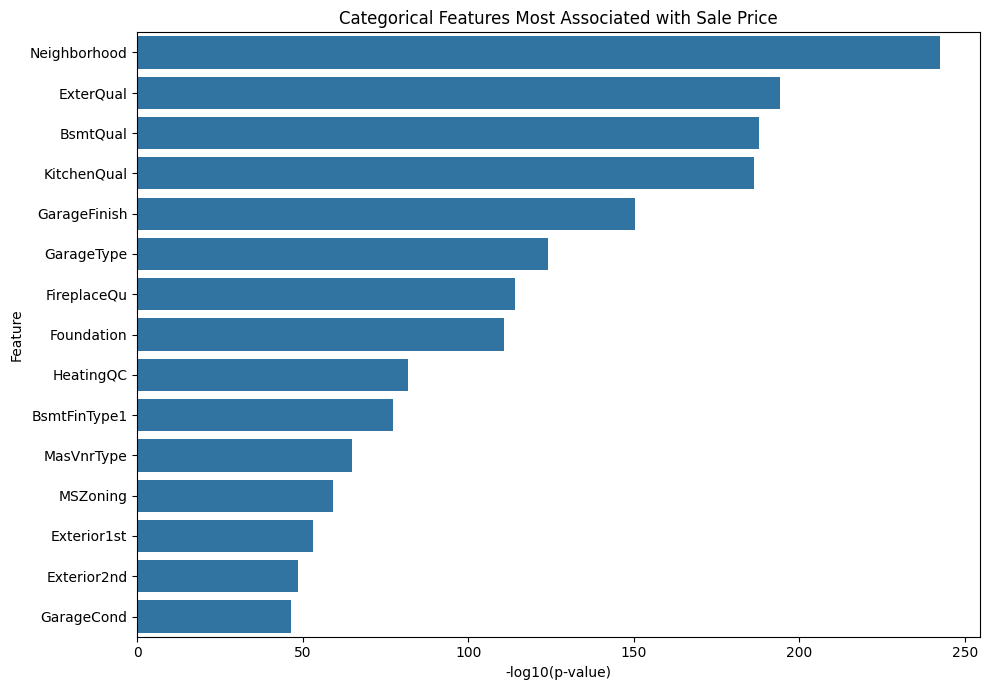

In [30]:
anova_results = categorical_anova(
    eda_data,
    cat_cols,
    "SalePrice_Log"
)

anova_results.head(15)

anova_plot = anova_results.head(15).copy()

anova_plot["-log10(p_value)"] = -np.log10(
    anova_plot["p_value"].clip(lower=1e-300)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=anova_plot,
    x="-log10(p_value)",
    y="feature"
)

plt.title("Categorical Features Most Associated with Sale Price")
plt.xlabel("-log10(p-value)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


### Categorical Feature Findings

ANOVA highlights meaningful price differences across categories, particularly for neighborhood, exterior quality, basement quality, and kitchen quality.

These relationships help guide categorical feature selection and encoding.


In [31]:
cat_strong = [ 'MSZoning', 'Neighborhood', 'Condition2', 'MasVnrType', 'ExterQual', 
                     'BsmtQual','CentralAir', 'Electrical', 'KitchenQual', 'SaleType']

cat_weak = ['Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 
                  'LandSlope', 'Condition1',  'BldgType', 'HouseStyle', 'RoofStyle', 
                  'RoofMatl', 'Exterior1st', 'Exterior2nd', 'ExterCond', 'Foundation', 
                  'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 
                  'HeatingQC', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 
                  'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 
                  'SaleCondition' ]

In [32]:
df = data_train.drop(
    columns=['Id', 'SalePrice_Log']
).copy()

y = data_train['SalePrice_Log'].copy()

df_test = data_test.drop(columns=['Id']).copy()

to_drop = cat_weak + cols_bel_corr_limit

df = df.drop(columns=to_drop)
df_test = df_test.drop(columns=to_drop)


## 5. Preprocessing & Validation

Data is split into **80% training / 20% holdout**, with **12-fold cross-validation** for model evaluation.

Preprocessing combines feature transformations with scikit-learn pipelines:

- **Numerical:** median imputation and standardization.
- **Ordinal:** ordered encoding of property quality ratings.
- **Nominal:** one-hot encoding.

Pipeline-based preprocessing prevents fitted transformations from leaking information across CV folds. Some feature transformations and selection steps are performed before the split and should be moved into the training-only workflow in future iterations.


In [33]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    df,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

cv = KFold(
    n_splits=12,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [34]:
ordinal_cols = [
    'ExterQual',
    'BsmtQual',
    'KitchenQual'
]

one_hot_cols = [
    'CentralAir',
    'MSZoning',
    'Neighborhood',
    'Condition2',
    'MasVnrType',
    'Electrical',
    'SaleType'
]

num_cols = [
    col for col in X_train.columns
    if col not in ordinal_cols + one_hot_cols
]

ordinal_dict = {
    'ExterQual': {'Ex' : 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1},
    'BsmtQual': {'None': 0,
        'Po': 1,
        'Fa': 2,
        'TA': 3,
        'Gd': 4,
        'Ex': 5},
    'KitchenQual': {'Ex' : 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None':0},
}

print(f"Numerical features: {len(num_cols)}")
print(f"Ordinal features: {len(ordinal_dict)}")
print(f"Nominal features: {len(one_hot_cols)}")

Numerical features: 15
Ordinal features: 3
Nominal features: 7


In [35]:
ordinal_categories = [
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
    ['None','Po', 'Fa', 'TA', 'Gd', 'Ex']
]

In [36]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

one_hot_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='None'
    )),
    ('ordinal', OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

In [37]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('ordinal', ordinal_pipeline, ordinal_cols),
    ('onehot', one_hot_pipeline, one_hot_cols)
])


## 6. Baseline Model

Linear Regression establishes an initial performance benchmark before evaluating regularized and tree-based models.

**Baseline Holdout RMSE: 0.13317** (log-transformed target).


In [38]:
linear_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_pipeline.fit(X_train, y_train)

y_pred = linear_pipeline.predict(X_test)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Baseline RMSE: {baseline_rmse:.5f}")

Baseline RMSE: 0.13306


In [39]:
print("X_train:", X_train.shape)
print("Missing columns:")

for name, transformer, columns in preprocessor.transformers:
    missing = set(columns) - set(X_train.columns)
    print(f"{name}: {missing}")

X_train: (1166, 25)
Missing columns:
num: set()
ordinal: set()
onehot: set()



## 7. Model Training & Hyperparameter Tuning

Models are optimized using `GridSearchCV` with **12-fold cross-validation** and negative RMSE as the scoring metric.



### 7.1 Regularized Linear Models

**Ridge** and **Lasso** are evaluated to control model complexity and reduce sensitivity to correlated predictors.


In [40]:
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('model', Ridge())
    
])

lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('model', Lasso(max_iter=50000, random_state=RANDOM_STATE))
    
])

In [41]:
def gridsearch(model, models, cv, X, y):
    
    grid = GridSearchCV(
        estimator=models[model][0],
        param_grid=models[model][1],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
        refit=True
    )
    
    grid.fit(X, y)
    
    return {
    "model": model,
    "best_params": grid.best_params_,
    "best_cv_rmse": -grid.best_score_,
    "best_cv_rmse_std": grid.cv_results_[
        "std_test_score"
    ][grid.best_index_],
    "best_estimator": grid.best_estimator_,
    "grid": grid
    }


def evaluate_model_cv(model, X, y, cv):
    scores = cross_validate(
        estimator=model,
        X=X,
        y=y,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=-1
    )

    train_rmse = -scores["train_rmse"]
    cv_rmse = -scores["test_rmse"]
    cv_mae = -scores["test_mae"]

    return {
        "Train RMSE": train_rmse.mean(),
        "CV RMSE": cv_rmse.mean(),
        "CV RMSE std": cv_rmse.std(),
        "CV MAE": cv_mae.mean(),
        "CV R2": scores["test_r2"].mean(),
        "Overfitting gap": cv_rmse.mean() - train_rmse.mean(),
        "Fit time": scores["fit_time"].mean()
    }

In [42]:

linear_models = {
    'Ridge': [
        ridge_pipeline,
        {
            'model__alpha': [
                25, 30, 35, 40, 45, 50,
                55, 60, 65, 70, 75
            ]
        }
    ],
    'Lasso': [
        lasso_pipeline,
        {
            'model__alpha': [
                1e-4, 3e-4, 5e-4, 1e-3,
                1e-2, 5e-2, 0.1, 0.3,
                1, 3, 5, 10, 15, 18,
                20, 30, 50, 75, 100
            ]
        }
    ]
}


In [43]:
linear_grid = {}

for model_name in linear_models:
    print(f"Tuning: {model_name}")

    result = gridsearch(
        model=model_name,
        models=linear_models,
        cv=cv,
        X=X_train,
        y=y_train
    )

    linear_grid[model_name] = result

    print(f"Best CV RMSE: {result['best_cv_rmse']:.5f}")
    print(f"Best params: {result['best_params']}")


Tuning: Ridge
Best CV RMSE: 0.13105
Best params: {'model__alpha': 60}
Tuning: Lasso
Best CV RMSE: 0.13062
Best params: {'model__alpha': 0.001}


In [44]:
linear_evaluation = {}

for model_name, result in linear_grid.items():
    linear_evaluation[model_name] = evaluate_model_cv(
        result['best_estimator'],
        X_train,
        y_train,
        cv
    )


### 7.2 Tree-Based Ensembles

Random Forest, Gradient Boosting, and Extra Trees are evaluated to capture nonlinear relationships and feature interactions.

Hyperparameter tuning focuses on tree complexity, ensemble size, and regularization-related settings.


In [45]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ))
])

extra_trees_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ("model", ExtraTreesRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

In [46]:
ensemble_models = {
    'Random Forest': [
        rf_pipeline,
        {
            'model__n_estimators': [100, 300, 600],
            'model__max_depth': [None, 2, 5, 15],
            'model__min_samples_leaf': [1, 2, 5],
            'model__max_features': ['sqrt', 0.7]
        }   
    ],
    'Gradient Boosting': [
        gb_pipeline,
        {
            'model__n_estimators': [100, 300, 700],
            'model__learning_rate': [0.01, 0.05, 0.1],
            'model__max_depth': [1, 2, 5],
            'model__min_samples_leaf': [2, 5, 10],
            'model__loss': ['huber', 'squared_error']
        }
    ],
    "Extra Trees": [
        extra_trees_pipeline,
        {
            "model__n_estimators": [300, 600],
            "model__max_depth": [None, 15],
            "model__min_samples_leaf": [1, 2],
            "model__max_features": ["sqrt", 0.7, 1.0]
        }
    ]
}

In [47]:
ensemble_grid = {}

for model_name in ensemble_models:
    print(f"Tuning: {model_name}")

    result = gridsearch(
        model=model_name,
        models=ensemble_models,
        cv=cv,
        X=X_train,
        y=y_train
    )

    ensemble_grid[model_name] = result

    print(f"Best CV RMSE: {result['best_cv_rmse']:.5f}")
    print(f"Best params: {result['best_params']}")
    print("-" * 60)

Tuning: Random Forest
Best CV RMSE: 0.13915
Best params: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 600}
------------------------------------------------------------
Tuning: Gradient Boosting
Best CV RMSE: 0.13055
Best params: {'model__learning_rate': 0.05, 'model__loss': 'huber', 'model__max_depth': 2, 'model__min_samples_leaf': 5, 'model__n_estimators': 700}
------------------------------------------------------------
Tuning: Extra Trees
Best CV RMSE: 0.13839
Best params: {'model__max_depth': 15, 'model__max_features': 0.7, 'model__min_samples_leaf': 2, 'model__n_estimators': 600}
------------------------------------------------------------


In [48]:
ensemble_evaluation = {}

for model_name, result in ensemble_grid.items():
    ensemble_evaluation[model_name] = evaluate_model_cv(
        model=result['best_estimator'],
        X=X_train,
        y=y_train,
        cv=cv
    )

ensemble_results = (
    pd.DataFrame(ensemble_evaluation)
    .T
    .sort_values('CV RMSE')
)

display(ensemble_results.round(4))

,Train RMSE,CV RMSE,CV RMSE std,CV MAE,CV R2,Overfitting gap,Fit time
Gradient Boosting,0.0980,0.1306,0.0148,0.0916,0.8838,0.0325,3.6505
Extra Trees,0.0469,0.1384,0.0216,0.0973,0.8693,0.0915,2.9535
Random Forest,0.0523,0.1391,0.0213,0.0959,0.8694,0.0868,2.1692


In [49]:
RES = {
    **linear_evaluation,
    **ensemble_evaluation
}

results_df = (
    pd.DataFrame.from_dict(RES, orient='index')
    .sort_values('CV RMSE')
)

display(results_df.round(4))

,Train RMSE,CV RMSE,CV RMSE std,CV MAE,CV R2,Overfitting gap,Fit time
Gradient Boosting,0.0980,0.1306,0.0148,0.0916,0.8838,0.0325,3.6505
Lasso,0.1207,0.1306,0.0135,0.0943,0.8845,0.0099,0.0302
Ridge,0.1210,0.1310,0.0141,0.0946,0.8840,0.0100,0.0263
Extra Trees,0.0469,0.1384,0.0216,0.0973,0.8693,0.0915,2.9535
Random Forest,0.0523,0.1391,0.0213,0.0959,0.8694,0.0868,2.1692



### Model Comparison — Key Findings

| Model | CV RMSE | Overfitting Gap |
|---|---:|---:|
| Gradient Boosting | 0.1306 | 0.0325 |
| Lasso | 0.1306 | 0.0099 |
| Ridge | 0.1310 | 0.0100 |
| Extra Trees | 0.1384 | 0.0915 |
| Random Forest | 0.1391 | 0.0868 |

**Key Observations:**
- **Gradient Boosting and Lasso** achieve the lowest CV RMSE.
- Lasso provides competitive accuracy with a smaller train–CV gap.
- Random Forest and Extra Trees show substantially greater overfitting.

Gradient Boosting and Lasso emerge as the strongest candidates at this stage.



### 7.3 XGBoost Optimization

XGBoost is evaluated as an additional gradient-boosted tree model, using histogram-based tree construction (`tree_method='hist'`).

Hyperparameters are optimized through `GridSearchCV`, with RMSE on log-transformed prices as the objective.


In [50]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        objective='reg:squarederror',
        eval_metric='rmse',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

xgb_param_grid = {
    'model__n_estimators': [500, 900],
    'model__learning_rate': [0.02, 0.05],
    'model__max_depth': [2, 3],
    'model__min_child_weight': [1, 3],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.7, 1.0],
    'model__reg_alpha': [0, 0.001],
    'model__reg_lambda': [1, 5]
}

In [51]:
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

best_xgb = xgb_grid.best_estimator_
best_xgb_cv_rmse = -xgb_grid.best_score_

print(f"Best CV RMSE: {best_xgb_cv_rmse:.5f}")
print(f"Best parameters: {xgb_grid.best_params_}")

Fitting 12 folds for each of 256 candidates, totalling 3072 fits
Best CV RMSE: 0.13093
Best parameters: {'model__colsample_bytree': 0.7, 'model__learning_rate': 0.02, 'model__max_depth': 2, 'model__min_child_weight': 1, 'model__n_estimators': 900, 'model__reg_alpha': 0.001, 'model__reg_lambda': 1, 'model__subsample': 0.8}


In [52]:
RES['XGBoost'] = evaluate_model_cv(
    best_xgb,
    X_train,
    y_train,
    cv
)

results_df = (
    pd.DataFrame.from_dict(RES, orient='index')
    .sort_values('CV RMSE')
)

display(results_df.round(4))

,Train RMSE,CV RMSE,CV RMSE std,CV MAE,CV R2,Overfitting gap,Fit time
Gradient Boosting,0.0980,0.1306,0.0148,0.0916,0.8838,0.0325,3.6505
Lasso,0.1207,0.1306,0.0135,0.0943,0.8845,0.0099,0.0302
XGBoost,0.1035,0.1309,0.0152,0.0931,0.8830,0.0274,0.3588
Ridge,0.1210,0.1310,0.0141,0.0946,0.8840,0.0100,0.0263
Extra Trees,0.0469,0.1384,0.0216,0.0973,0.8693,0.0915,2.9535
Random Forest,0.0523,0.1391,0.0213,0.0959,0.8694,0.0868,2.1692



### Final Cross-Validation Results

| Model | CV RMSE | CV R² |
|---|---:|---:|
| Gradient Boosting | 0.1306 | 0.8838 |
| Lasso | 0.1306 | 0.8845 |
| XGBoost | 0.1309 | 0.8830 |
| Ridge | 0.1310 | 0.8840 |
| Extra Trees | 0.1384 | 0.8693 |
| Random Forest | 0.1391 | 0.8694 |

**Key Findings:**
- **Gradient Boosting and Lasso** achieve the best CV RMSE (**0.1306**).
- XGBoost remains highly competitive at **0.1309**.
- Lasso demonstrates that a simpler model can match complex ensembles.
- Random Forest and Extra Trees generalize less effectively.

XGBoost is selected for the final submission, although it does not achieve the lowest CV error.



## 8. Final Model & Kaggle Submission

The tuned XGBoost model is evaluated on the 20% holdout set before being refitted on all available training observations.

**Holdout RMSE: 0.12611** (log-transformed target).

Final predictions are converted back to sale prices using `expm1` and exported as `submission.csv`.


In [53]:
final_model = best_xgb

final_model.fit(X_train, y_train)

holdout_pred = final_model.predict(X_test)
holdout_rmse = np.sqrt(
    mean_squared_error(y_test, holdout_pred)
)

print(f"Holdout RMSE: {holdout_rmse:.5f}")

final_model.fit(df, y)

pred_log = final_model.predict(df_test)
pred = np.expm1(pred_log)


Holdout RMSE: 0.12611


In [54]:
test_ids = pd.read_csv(
    '/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv',
    usecols=['Id']
)['Id']

submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': pred
})

assert len(submission) == len(df_test)
assert submission['SalePrice'].notna().all()

submission.to_csv('submission.csv', index=False)



## 9. Conclusions

**Final Kaggle Leaderboard RMSLE: 0.14772**

The project demonstrates an end-to-end regression workflow combining exploratory analysis, feature transformations, preprocessing pipelines, cross-validation, and hyperparameter tuning.

**Main Takeaways:**
- Log-transforming `SalePrice` reduces target skewness.
- Gradient Boosting and Lasso achieve the best CV RMSE (**0.1306**).
- XGBoost delivers a competitive CV RMSE (**0.1309**) and a holdout RMSE of **0.12611**.
- Simpler regularized models can perform as well as more complex ensembles.
- The final Kaggle submission achieves an **RMSLE of 0.14772**.

**Future Improvements:**
- Move target-informed feature selection and outlier handling into the training-only workflow.
- Use repeated or nested validation to assess tuning stability.
